# Breakfast Hour - Monday, Week 2

### Data Visualization Review (Matplotlib & Seaborn)

Author: Katie Sylvia, Loren Dunn, RS

Data set in the data folder as `auto_mpg_dataset.csv`. Dataset is of cars from the 1970s and 1980s.<br>
Data from: https://www.mldata.io/datasets-sort/regression/<br>

This data has <a href="https://archive.ics.uci.edu/ml/datasets/auto+mpg">academic origins.  (Carnegie Mellon StatLib Library.)</a> For today, we'll pretend we've been given this data by the product team.

In [106]:
# Import Libraries 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [107]:
# Read in the data
df = pd.read_csv('./data/auto_mpg_dataset.csv')

In [108]:
# Check .info(). What does this tell us?


In [38]:
# Display the first 5 rows


## Data Cleaning

Before starting a project, do a quick audit of your data. This will help you set expectations and plan your time.

Is the data:
1. *There?*
2. Typo-free?
3. Reasonable?


#### 1. *There*, and in the correct format

In [94]:
# Check for null values


In [7]:
# Check datatypes


In [113]:
# Check duplicates


#### 2. Typo-free

In [1]:
# Check the make of the car. Return all unique values for the first word in the string.


I asked ChatGPT to fix it. Do you notice any problems with the dictionary it wrote for me?

In [ ]:
gpt_dict = {'chevroelt': 'chevrolet', 'hi': 'honda', 'maxda': 'mazda', 'toyouta': 'toyota', 'vokswagen': 'volkswagen'} 

# Problems

In [79]:
df[df['car_name'].str.contains("hi")]

,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name,mpg
28,8,304.0,193.0,4732.0,18.5,70,1,hi 1200d,9.0


In [80]:
# Fix it

new_dict =  { }

In [119]:
# Map replacement text
df['car_name'] = df['car_name'].apply(lambda x:" ".join(new_dict.get(i, i) for i in x.split()))

# Check
print(sorted(list(df['car_name'].apply(lambda x:x.split()[0]).unique())))

In [ ]:
# What does this tell us about our data?:

# 

#### 3. Reasonable

In [ ]:
# Fill out the car facts table

| 1980s  🚗s      | reasonable values | notes/questions |
| ----------- | ----------- | ----------- |
| mpg      | ? - ?       |  Text        |
| horsepower   | ? - ?        |  Text        |
| weight   | ? - ?        |  Text        |
| cylinders   | ? - ?        |  Text        |
| acceleration   | ? - ?        |  Text        |

In [ ]:
# Boxplots


In [2]:
# What info can you get from a .describe(), and why does it matter?


In [100]:
# Filter for negative horsepower


,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name,mpg
32,4,98.0,-100000.0,2046.0,19.0,71,1,ford pinto,25.0
126,6,200.0,-100000.0,2875.0,17.0,74,1,ford maverick,21.0
330,4,85.0,-100000.0,1835.0,17.3,80,2,renault lecar deluxe,40.9
336,4,140.0,-100000.0,2905.0,14.3,80,1,ford mustang cobra,23.6
354,4,100.0,-100000.0,2320.0,15.8,81,2,renault 18i,34.5
374,4,151.0,-100000.0,3035.0,20.5,82,1,amc concord dl,23.0


In [118]:
# Dropping the data is not ideal. I'm going to do it anyways

len(df[df['horsepower']<0])/len(df)

0.01507537688442211

In [102]:
df = df[df['horsepower']>0].copy() # What is the purpose of .copy()?

We can drop the categorical columns.

In [ ]:
# In the correct format
 # Do you need to merge dataframes?
 # Rename columns?

## Correlations 🔥

No pearson correlations on categorical data! <a href='https://www.jstor.org/stable/2094532'>And be careful with ordinal data.</a>
- If x is continuous and y is binary, that's <a href='https://en.wikipedia.org/wiki/Point-biserial_correlation_coefficient'> point biserial</a>
- if x and y are both binary, that's <a href='https://en.wikipedia.org/wiki/Phi_coefficient'>phi coefficient</a>
- if multiple categories are in the same column and coded on a numeric scale, that's a <a href='https://en.wikipedia.org/wiki/Mistake'><b>mistake</b></a>!

In [116]:
# df.corr()


,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,mpg
cylinders,1.000000,0.950721,0.084291,0.896017,-0.505419,-0.348746,-0.562543,-0.775396
displacement,0.950721,1.000000,0.079333,0.932824,-0.543684,-0.370164,-0.609409,-0.804203
horsepower,0.084291,0.079333,1.000000,0.071114,-0.080685,-0.067952,0.035575,-0.073501
weight,0.896017,0.932824,0.071114,1.000000,-0.417457,-0.306564,-0.581024,-0.831741
acceleration,-0.505419,-0.543684,-0.080685,-0.417457,1.000000,0.288137,0.205873,0.420289
model_year,-0.348746,-0.370164,-0.067952,-0.306564,0.288137,1.000000,0.180662,0.579267
origin,-0.562543,-0.609409,0.035575,-0.581024,0.205873,0.180662,1.000000,0.563450
mpg,-0.775396,-0.804203,-0.073501,-0.831741,0.420289,0.579267,0.563450,1.000000


In [11]:
# Seaborn heatmap()


In [8]:
# A bit more beautiful
plt.figure(figsize = )

sns.heatmap(data = , 
            annot = ,          # adds numbers
            vmin = ,           # sets the scale for the colormap
            vmax = );

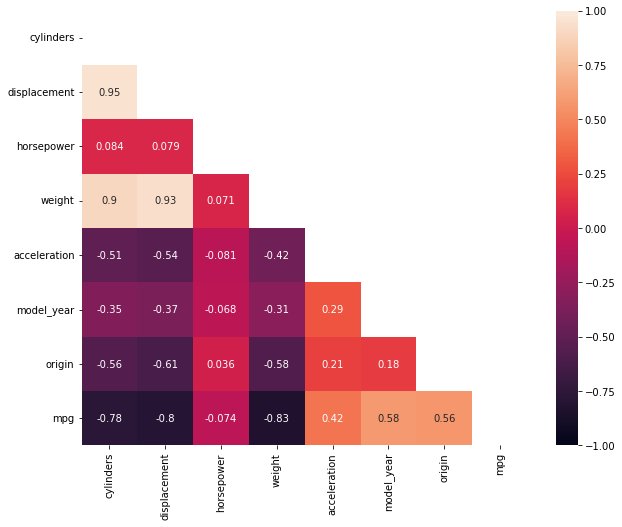

In [117]:
# A bit redundant... let's remove that!

mask = np.zeros_like(df.corr())           # Creates an empty array that's the same size as the given array
mask[np.triu_indices_from(mask)] = True   # Numpy function, grabs the indices of the upper triangle of the array.

In [14]:
# What if we ONLY wanted to look at how the features correlate with `mpg`?


In [15]:
# Can we throw this in a heatmap?


#### Take a look at your parameters and play around with them! Ex | vmin, vmax, cmap, etc.



For more Seaborn color palettes, click [here](https://seaborn.pydata.org/tutorial/color_palettes.html).

## Countplots 🔢

**Distribution of Model Year**

In [16]:
# Seaborn .countplot()

plt.figure(figsize = )

sns.countplot(data = , 
              x = , 
              palette = ,)

# Add a title

# Add xlabels

# add ylabels

;

*Why can we mix up seaborn and matplotlib like this? Seaborn is using matplotlib under the hood.*

**Distribution of Cylinders**

In [17]:
# How can we get the bars in order? Use the "order" parameter!
df['cylinders'].value_counts().index

## Boxplots 📦

**MPG Distribution**

In [ ]:
# Seaborn .boxplot()

plt.figure(figsize = (8, 5))
sns.boxplot(data = , 
            x = )

plt.title('MPG Boxplot');

In [ ]:
# Something looks familiar...
df['mpg'].describe() 

**Weight Distribution**

## Barplots 📊

**Average MPG by Number of Cylinders**

In [122]:
#Let's review... how do we use .groupby()?


In [19]:
# One step further -- we just want the `mpg` column!


In [123]:
# Check out .index and .values. How can we get the "order"?


In [20]:
# Quick Plot w/ Pandas


In [21]:
# Seaborn .barplot()

plt.figure(figsize = (8,5))
sns.barplot(data = df,
            x = ,
            y = ,
            order = ,
            palette = 'Paired'
           )

# add a title, xlabel, and ylabel*:



## Scatterplots 🐜

**Weight vs. MPG**

In [22]:
# Matplotlib .scatter()

plt.figure(figsize = (8,5))
plt.scatter(data = ,
           x = ,
           y = )

# add title, xlabel, ylabel


In [23]:
# Seaborn .scatterplot()

plt.figure(figsize = (8,5))
sns.scatterplot(data = ,
               x = ,
               y = ,
               )

# add title, xlabel, ylabel

# Check out the other parameters you have available

## Your turn!

In [24]:
# Create more plot(s) of your choosing to help you explore the data

# Upcoming This Week - Machine Learning!

Use Linear Regression to predict `mpg` from the other features<br>